# Stride labels

Finds one gz peak per stride with `python/detector.py` (the same code the board
runs), checks 2 x strides against the step count N typed in for each recording,
and saves the stride times to `data/strides.csv`. The cadence labels for
training come from those times through `laptop/cadence.py`.

1. Load recordings and detect strides
2. Stride plots
3. Cadence labels
4. Save

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../../python")
sys.path.insert(0, "..")
from detector import HIGH, LOW, find_strides
from cadence import cadence, phase_knots

DATA_DIR = Path("../../data")
WIN_S = 4.0
HOP_S = 0.5

# Hand fixes after detection, stride peak times in seconds from the file start
FIXES = {}   # e.g. {"walk_07.csv": {"add": [12.3], "remove": [50.8]}}

## 1. Load and detect

In [2]:
steps = pd.read_csv(DATA_DIR / "steps.csv").set_index("file").steps
recs = {}
for p in sorted(DATA_DIR.glob("*_*.csv")):
    df = pd.read_csv(p)
    df["t"] = (df.t_ms - df.t_ms.iloc[0]) / 1000.0
    s = (np.array(find_strides(df.t_ms, df.gz)) - df.t_ms.iloc[0]) / 1000.0
    fix = FIXES.get(p.name, {})
    s = [x for x in s if not any(abs(x - r) < 0.1 for r in fix.get("remove", []))]
    s = np.sort(np.array(s + list(fix.get("add", []))))
    recs[p.name] = (df, s)

table = pd.DataFrame([
    {"file": f, "N": steps.get(f), "detected": 2 * len(s)} for f, (df, s) in recs.items()
]).set_index("file")
table["diff"] = table.detected - table.N
table["ok"] = np.where(table["diff"].abs() <= 1, "✓", "CHECK")
table

,N,detected,diff,ok
file,,,,
still_01.csv,0,0,0,✓
still_02.csv,0,0,0,✓
walk_01.csv,225,226,1,✓
walk_02.csv,210,210,0,✓
walk_03.csv,62,62,0,✓
walk_04.csv,250,250,0,✓
walk_05.csv,236,236,0,✓
walk_06.csv,56,56,0,✓
walk_07.csv,186,186,0,✓


## 2. Stride plots

gz with detected stride peaks. Dashed lines are the detector's HIGH and LOW thresholds.

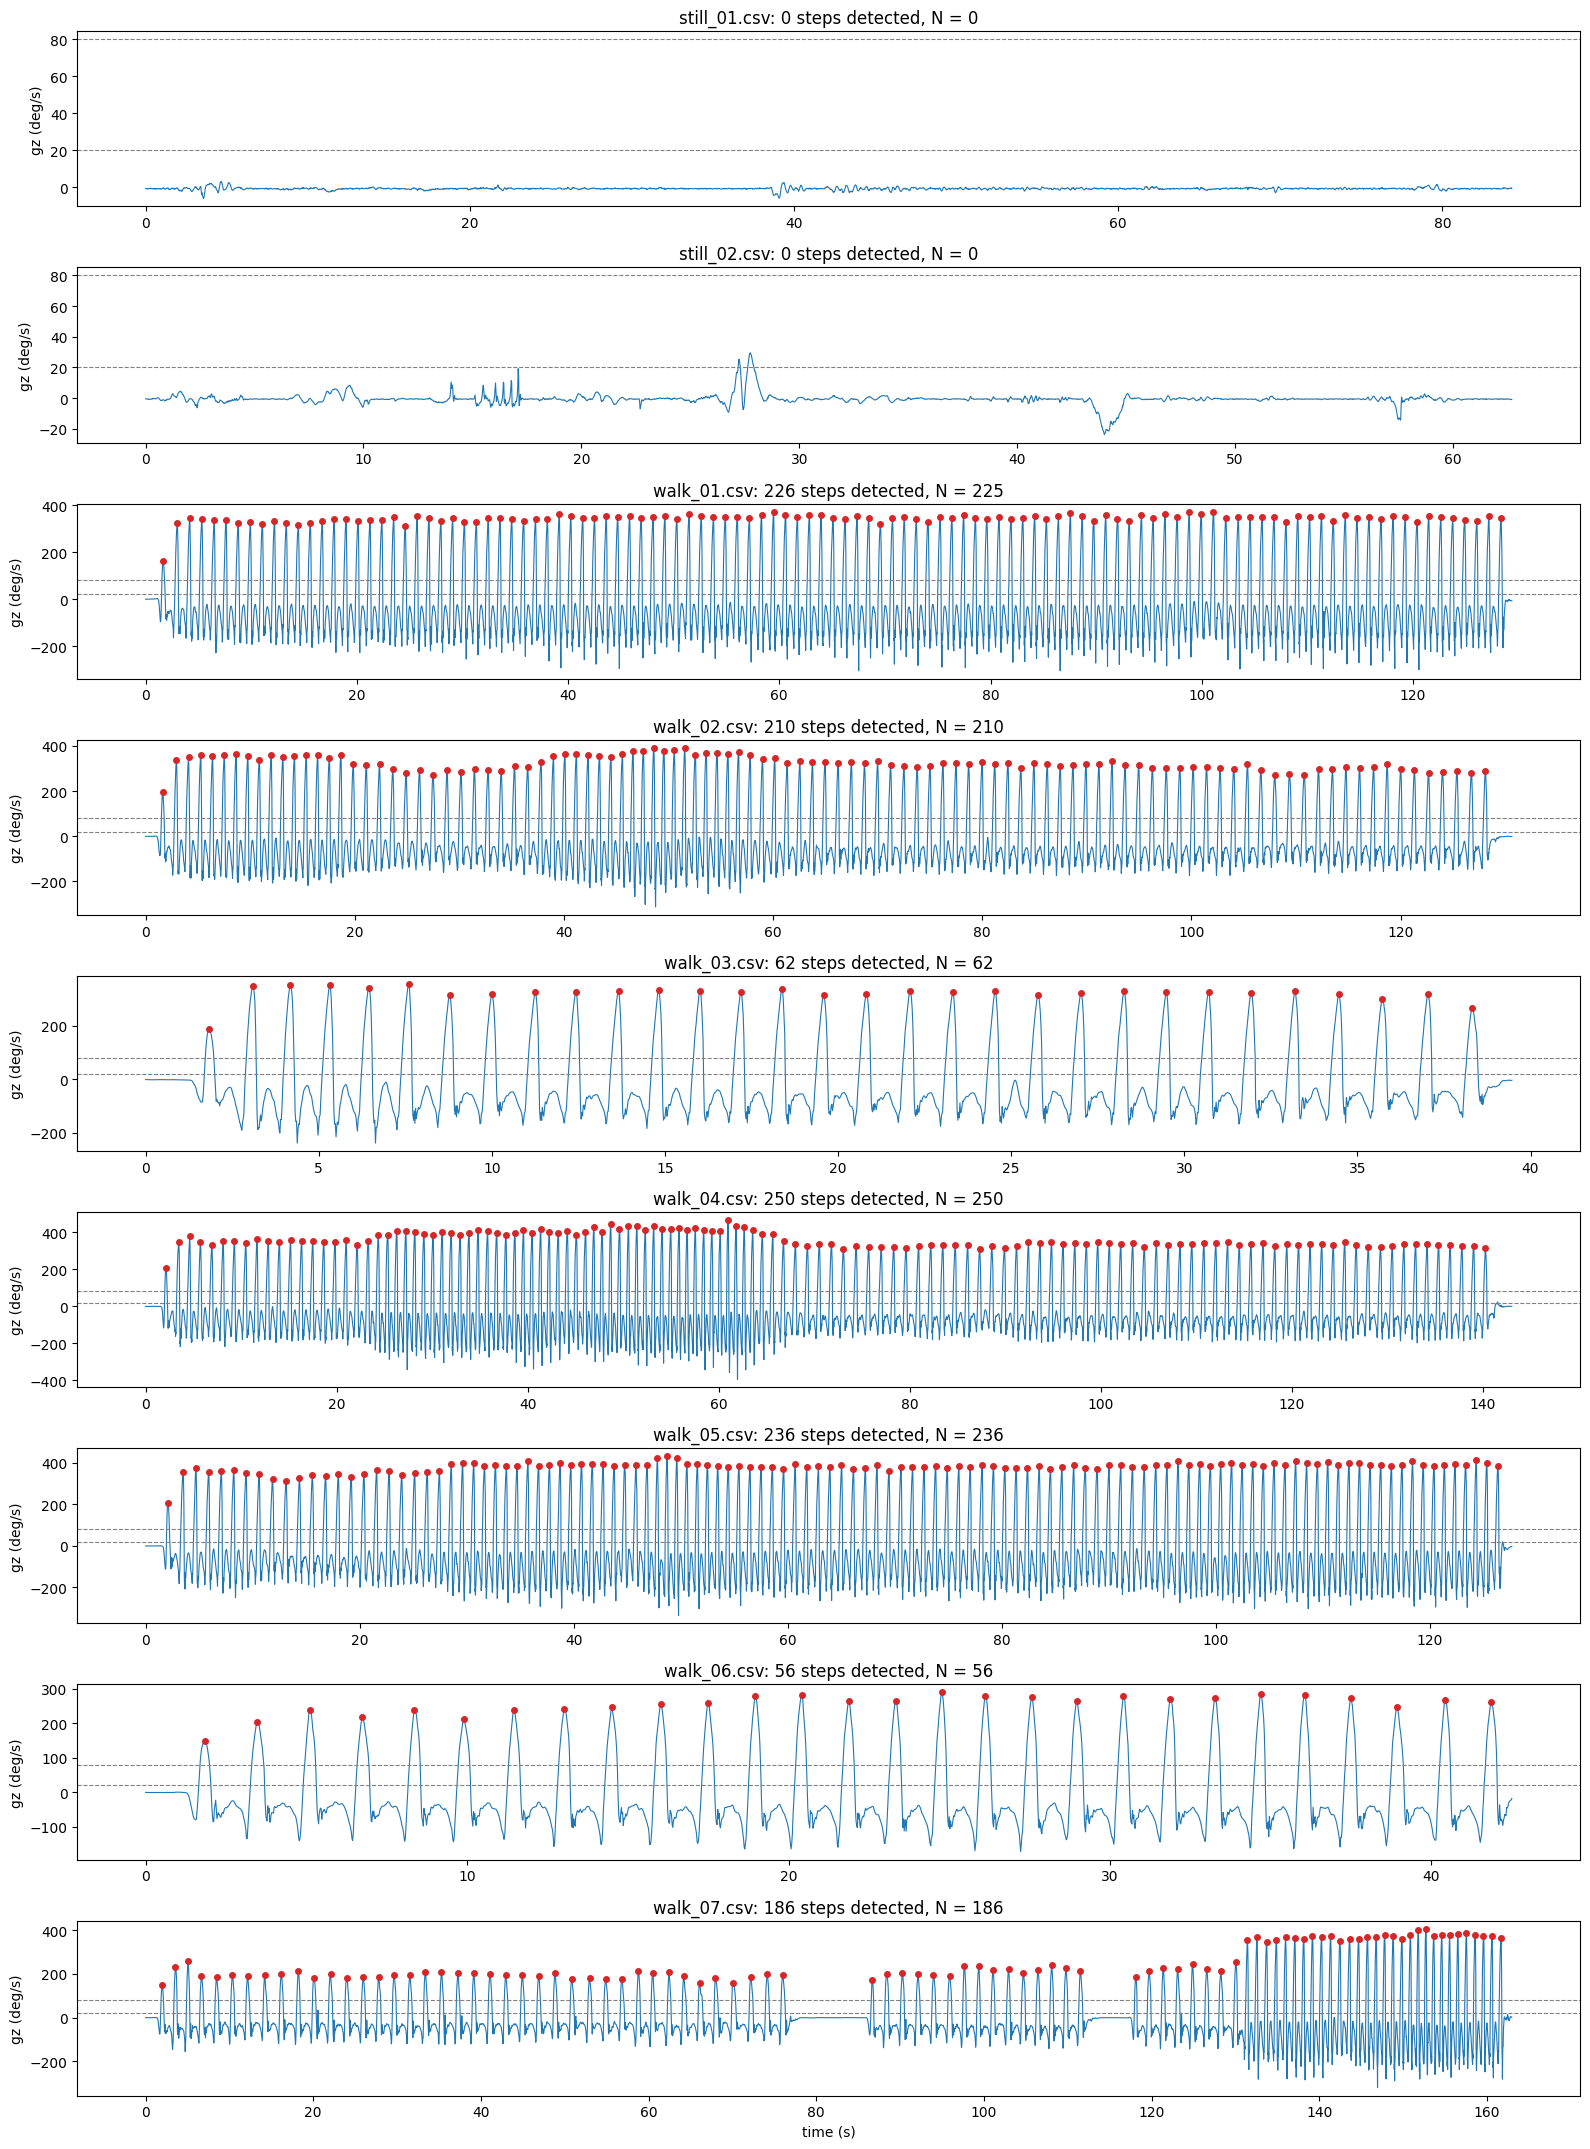

In [3]:
fig, axs = plt.subplots(len(recs), 1, figsize=(16, 2.4 * len(recs)))
for ax, (f, (df, s)) in zip(axs, recs.items()):
    ax.plot(df.t, df.gz, lw=0.8)
    ax.plot(s, np.interp(s, df.t, df.gz), "o", ms=4, color="C3")
    for y in (HIGH, LOW):
        ax.axhline(y, ls="--", lw=0.8, color="grey")
    ax.set_title(f"{f}: {2 * len(s)} steps detected, N = {steps.get(f)}")
    ax.set_ylabel("gz (deg/s)")
axs[-1].set_xlabel("time (s)")
fig.tight_layout()

## 3. Cadence labels

Label for each 4 s window, stepped every 0.5 s, plotted at the window's
end time (what the board will know at that moment). Should sit around 1.4-2.0
steps/s while walking and drop to 0 in pauses and still files.

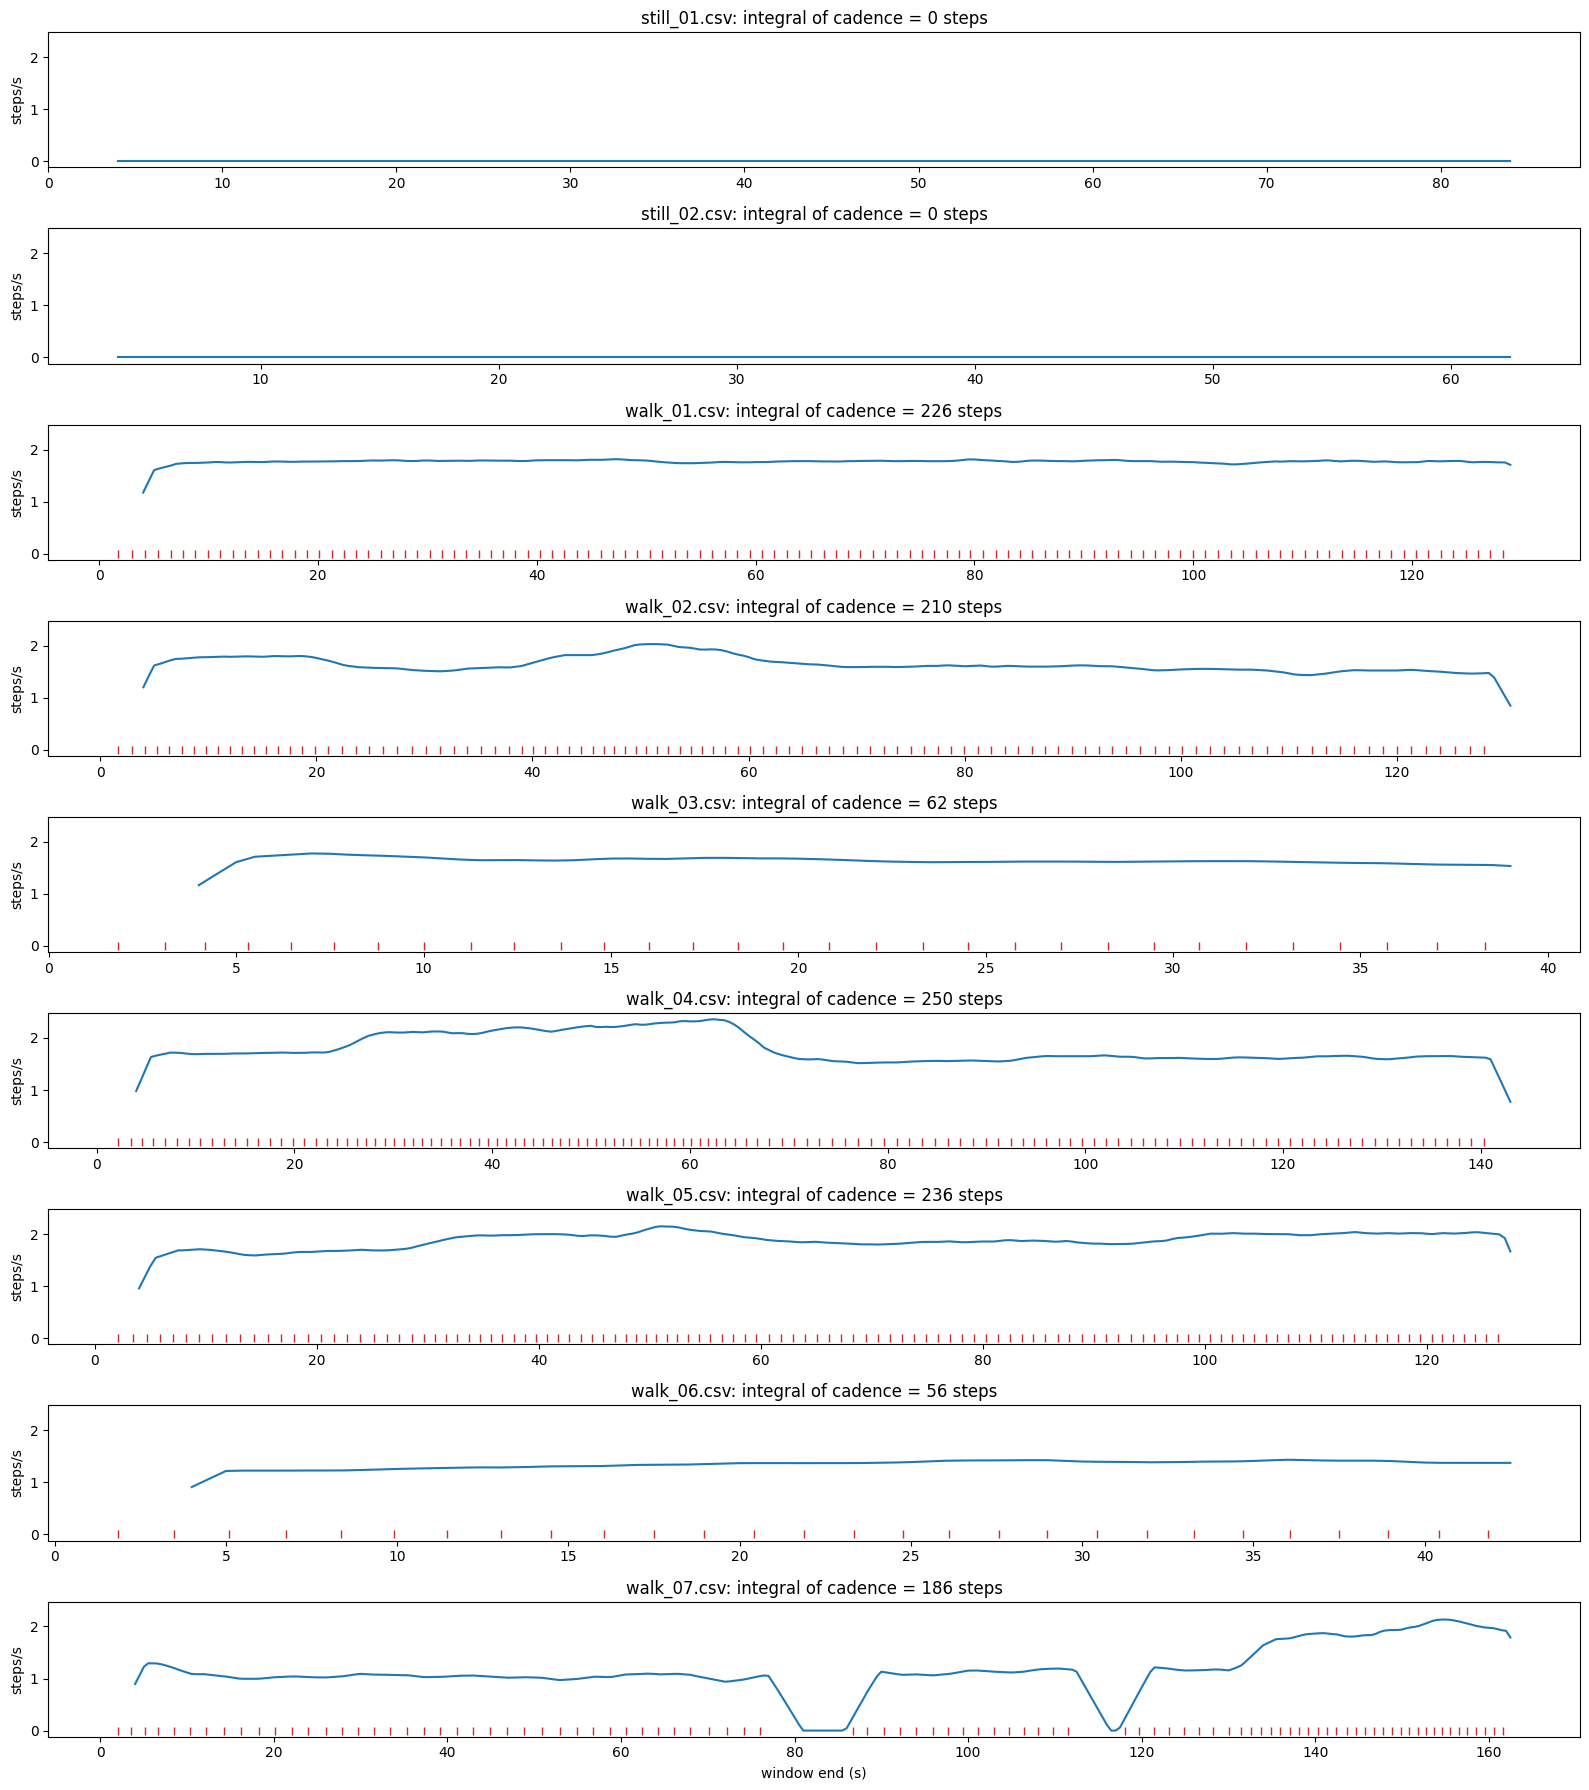

In [4]:
fig, axs = plt.subplots(len(recs), 1, figsize=(16, 2 * len(recs)), sharey=True)
for ax, (f, (df, s)) in zip(axs, recs.items()):
    knots = phase_knots(s)
    ends = np.arange(WIN_S, df.t.iloc[-1], HOP_S)
    c = cadence(ends - WIN_S, ends, knots)
    ax.plot(ends, c)
    ax.plot(s, np.zeros_like(s), "|", color="C3")
    total = 2 * (knots[1][-1] - knots[1][0])
    ax.set_title(f"{f}: integral of cadence = {total:.0f} steps")
    ax.set_ylabel("steps/s")
axs[-1].set_xlabel("window end (s)")
fig.tight_layout()

## 4. Save

In [5]:
rows = [
    {"file": f, "t_ms": int(round(df.t_ms.iloc[0] + 1000 * x))}
    for f, (df, s) in recs.items() for x in s
]
pd.DataFrame(rows, columns=["file", "t_ms"]).to_csv(DATA_DIR / "strides.csv", index=False)
print(f"saved {len(rows)} strides")

saved 613 strides
